<a href="https://colab.research.google.com/github/Nhut214/vietnamese_student_feedback_sentiment_analysis/blob/main/notebooks/02_Maximum_Entropy_UIT_VSFC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Đường dẫn dữ liệu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data
Train: (11426, 3)
Validation: (1583, 3)
Test: (3166, 3)

Phân bố nhãn tập train:
sentiment
Negative    5325
Neutral      458
Positive    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


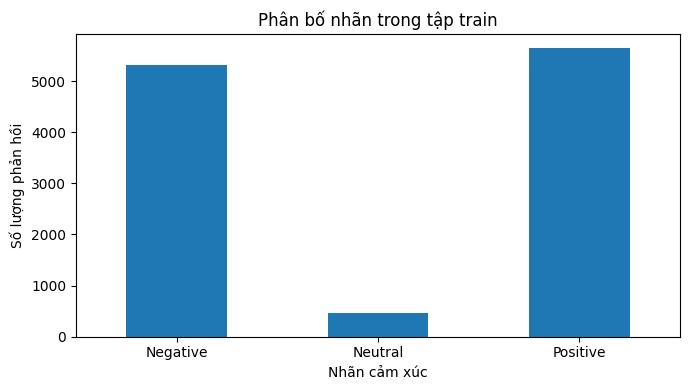

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}

DATA_DIR = r"/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VALIDATION_PATH = os.path.join(DATA_DIR, "validation.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}\n"
            "Hãy kiểm tra lại tên thư mục và tên file trong Google Drive."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

def clean_dataframe(df, name):
    required_columns = {"sentence", "sentiment"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Tập {name} thiếu các cột bắt buộc: {missing_columns}"
        )

    cleaned = df.dropna(subset=["sentence", "sentiment"]).copy()
    cleaned["sentence"] = cleaned["sentence"].astype(str).str.strip()
    cleaned["sentiment"] = pd.to_numeric(
        cleaned["sentiment"],
        errors="coerce"
    )
    cleaned = cleaned.dropna(subset=["sentiment"])
    cleaned["sentiment"] = cleaned["sentiment"].astype(int)
    cleaned = cleaned[
        cleaned["sentiment"].isin(LABEL_IDS)
    ]
    cleaned = cleaned[
        cleaned["sentence"].str.len() > 0
    ].reset_index(drop=True)

    return cleaned

train_df = clean_dataframe(train_df, "train")
val_df = clean_dataframe(val_df, "validation")
test_df = clean_dataframe(test_df, "test")

# Các biến nhãn được tạo ngay sau khi đọc dữ liệu.
y_train = train_df["sentiment"].to_numpy(dtype=np.int64)
y_val = val_df["sentiment"].to_numpy(dtype=np.int64)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

print("Đường dẫn dữ liệu:", DATA_DIR)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nPhân bố nhãn tập train:")
print(
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

display(train_df.head())

train_counts = (
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

train_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Phân bố nhãn trong tập train")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng phản hồi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

RESULTS = []

def evaluate_predictions(
    model_name,
    experiment,
    y_true,
    y_pred,
    show_confusion_matrix=True
):
    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        average="weighted",
        zero_division=0
    )

    class_precision, class_recall, class_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average=None,
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Experiment": experiment,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Negative Precision": class_precision[0],
        "Negative Recall": class_recall[0],
        "Negative F1": class_f1[0],
        "Neutral Precision": class_precision[1],
        "Neutral Recall": class_recall[1],
        "Neutral F1": class_f1[1],
        "Positive Precision": class_precision[2],
        "Positive Recall": class_recall[2],
        "Positive F1": class_f1[2],
        "Neutral Support": int(support[1]),
    }

    RESULTS.append(result)

    print(f"\n{model_name} — {experiment}")
    print("=" * 72)
    print(
        classification_report(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0
        )
    )

    if show_confusion_matrix:
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )
        display_matrix = ConfusionMatrixDisplay(
            matrix,
            display_labels=LABEL_NAMES
        )
        display_matrix.plot(values_format="d")
        plt.title(f"{model_name} — {experiment}")
        plt.tight_layout()
        plt.show()

    return result


def export_results(filename):
    if not RESULTS:
        raise ValueError("Chưa có kết quả để xuất.")

    result_df = (
        pd.DataFrame(RESULTS)
        .drop_duplicates(
            subset=["Model", "Experiment"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    metric_columns = [
        column
        for column in result_df.columns
        if column not in [
            "Model",
            "Experiment",
            "Neutral Support"
        ]
    ]

    display_df = result_df.copy()
    display_df[metric_columns] = (
        display_df[metric_columns].round(4)
    )

    display(display_df)

    output_path = os.path.join(
        "/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC",
        filename
    )
    result_df.to_csv(output_path, index=False)

    print("Đã lưu kết quả tại:", output_path)
    return result_df



## 1. Tạo đặc trưng TF-IDF

Maximum Entropy được triển khai bằng Logistic Regression đa lớp.


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
    lowercase=False
)

X_train = tfidf.fit_transform(
    train_df["sentence"].astype(str)
)
X_val = tfidf.transform(
    val_df["sentence"].astype(str)
)
X_test = tfidf.transform(
    test_df["sentence"].astype(str)
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)


X_train: (11426, 13154)
y_train: (11426,)
X_val: (1583, 13154)
y_val: (1583,)
X_test: (3166, 13154)
y_test: (3166,)



## 2. Maximum Entropy trên dữ liệu gốc



Maximum Entropy — Baseline
              precision    recall  f1-score   support

    Negative     0.8517    0.9702    0.9071      1409
     Neutral     0.8000    0.0719    0.1319       167
    Positive     0.9327    0.9069    0.9196      1590

    accuracy                         0.8910      3166
   macro avg     0.8615    0.6497    0.6529      3166
weighted avg     0.8897    0.8910    0.8725      3166



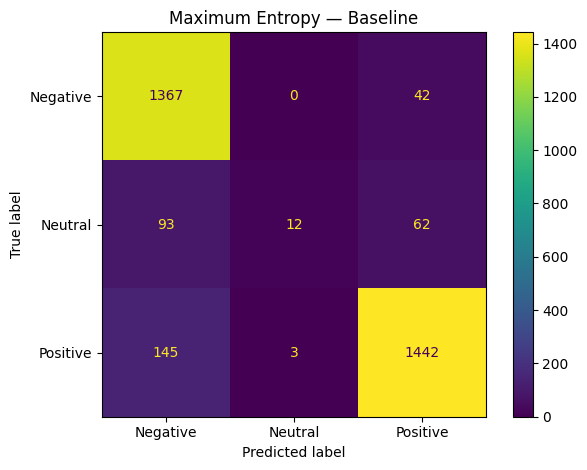

{'Model': 'Maximum Entropy',
 'Experiment': 'Baseline',
 'Accuracy': 0.8910296904611498,
 'Macro Precision': 0.8614810068256405,
 'Macro Recall': 0.6496553838950022,
 'Macro F1': 0.6528703960273304,
 'Weighted F1': 0.8725073598768676,
 'Negative Precision': np.float64(0.8517133956386292),
 'Negative Recall': np.float64(0.9701916252661462),
 'Negative F1': np.float64(0.907100199071002),
 'Neutral Precision': np.float64(0.8),
 'Neutral Recall': np.float64(0.0718562874251497),
 'Neutral F1': np.float64(0.13186813186813187),
 'Positive Precision': np.float64(0.9327296248382924),
 'Positive Recall': np.float64(0.9069182389937107),
 'Positive F1': np.float64(0.9196428571428571),
 'Neutral Support': 167}

In [ ]:

model_maxent_baseline = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    random_state=SEED
)

model_maxent_baseline.fit(X_train, y_train)

pred_maxent_baseline = (
    model_maxent_baseline.predict(X_test)
)

evaluate_predictions(
    "Maximum Entropy",
    "Baseline",
    y_test,
    pred_maxent_baseline
)



## 3. Maximum Entropy sử dụng trọng số lớp



Maximum Entropy — Class Weight
              precision    recall  f1-score   support

    Negative     0.8665    0.9120    0.8887      1409
     Neutral     0.2982    0.4072    0.3443       167
    Positive     0.9519    0.8711    0.9097      1590

    accuracy                         0.8648      3166
   macro avg     0.7055    0.7301    0.7142      3166
weighted avg     0.8794    0.8648    0.8705      3166



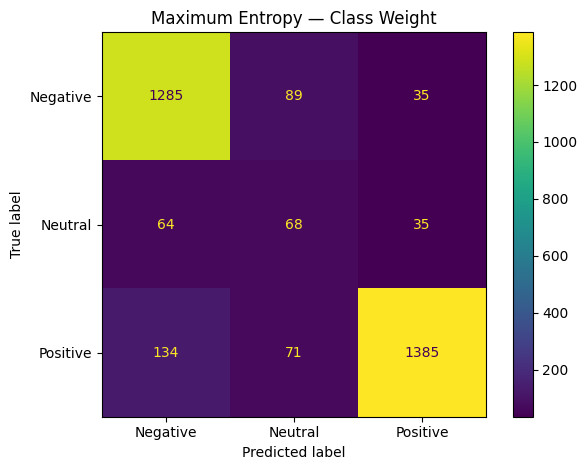

{'Model': 'Maximum Entropy',
 'Experiment': 'Class Weight',
 'Accuracy': 0.86481364497789,
 'Macro Precision': 0.7055408331256988,
 'Macro Recall': 0.7300830444489295,
 'Macro F1': 0.7142167261720411,
 'Weighted F1': 0.8705061009005653,
 'Negative Precision': np.float64(0.8664868509777478),
 'Negative Recall': np.float64(0.9119943222143364),
 'Negative F1': np.float64(0.8886583679114799),
 'Neutral Precision': np.float64(0.2982456140350877),
 'Neutral Recall': np.float64(0.40718562874251496),
 'Neutral F1': np.float64(0.34430379746835443),
 'Positive Precision': np.float64(0.9518900343642611),
 'Positive Recall': np.float64(0.8710691823899371),
 'Positive F1': np.float64(0.909688013136289),
 'Neutral Support': 167}

In [ ]:

model_maxent_balanced = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED
)

model_maxent_balanced.fit(X_train, y_train)

pred_maxent_balanced = (
    model_maxent_balanced.predict(X_test)
)

evaluate_predictions(
    "Maximum Entropy",
    "Class Weight",
    y_test,
    pred_maxent_balanced
)


In [ ]:

maximum_entropy_results = export_results(
    "maximum_entropy_results.csv"
)


,Model,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Negative Precision,Negative Recall,Negative F1,Neutral Precision,Neutral Recall,Neutral F1,Positive Precision,Positive Recall,Positive F1,Neutral Support
0,Maximum Entropy,Baseline,0.8910,0.8615,0.6497,0.6529,0.8725,0.8517,0.9702,0.9071,0.8000,0.0719,0.1319,0.9327,0.9069,0.9196,167
1,Maximum Entropy,Class Weight,0.8648,0.7055,0.7301,0.7142,0.8705,0.8665,0.9120,0.8887,0.2982,0.4072,0.3443,0.9519,0.8711,0.9097,167


Đã lưu kết quả tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/maximum_entropy_results.csv


In [ ]:
import os
import json

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "NC_MatCanBang_UIT_VSFC/"
    "SavedModels/"
    "maximum_entropy_weighted"
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

MAXENT_JSON_PATH = os.path.join(
    SAVE_DIR,
    "maxent_model.json"
)

maxent_data = {
    "model_type": "Maximum Entropy",
    "implementation": "LogisticRegression",
    "scenario": "Class Weight",

    "labels": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    },

    "classes": [
        int(x)
        for x in model_maxent_balanced.classes_
    ],

    # Ma trận trọng số của Logistic Regression
    "coef": [
        [
            float(value)
            for value in row
        ]
        for row in model_maxent_balanced.coef_
    ],

    # Bias của từng lớp
    "intercept": [
        float(x)
        for x in model_maxent_balanced.intercept_
    ],

    "tfidf": {
        "vocabulary": {
            str(token): int(index)
            for token, index
            in tfidf.vocabulary_.items()
        },

        "idf": [
            float(x)
            for x in tfidf.idf_
        ],

        "ngram_range": [
            int(x)
            for x in tfidf.ngram_range
        ],

        "sublinear_tf": bool(
            tfidf.sublinear_tf
        ),

        "lowercase": bool(
            tfidf.lowercase
        ),

        "norm": str(
            tfidf.norm
        ),

        "token_pattern": str(
            tfidf.token_pattern
        )
    }
}


with open(
    MAXENT_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        maxent_data,
        f,
        ensure_ascii=False
    )


print(
    "Đã lưu:",
    MAXENT_JSON_PATH
)

print(
    "Dung lượng:",
    round(
        os.path.getsize(
            MAXENT_JSON_PATH
        ) / (1024 ** 2),
        2
    ),
    "MB"
)

Đã lưu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/maximum_entropy_weighted/maxent_model.json
Dung lượng: 1.3 MB


In [ ]:
print(
    "Có file:",
    os.path.exists(
        MAXENT_JSON_PATH
    )
)

print(
    "Số đặc trưng:",
    len(
        maxent_data[
            "tfidf"
        ][
            "vocabulary"
        ]
    )
)

print(
    "Số lớp:",
    len(
        maxent_data[
            "classes"
        ]
    )
)

print(
    "Kích thước coef:",
    model_maxent_balanced.coef_.shape
)

print(
    "Kích thước intercept:",
    model_maxent_balanced.intercept_.shape
)

Có file: True
Số đặc trưng: 13154
Số lớp: 3
Kích thước coef: (3, 13154)
Kích thước intercept: (3,)


In [ ]:
import numpy as np

text_test = "giảng viên nhiệt tình"

X_demo = tfidf.transform(
    [text_test]
)

# =========================
# 1. Kết quả sklearn
# =========================

sklearn_probs = (
    model_maxent_balanced
    .predict_proba(X_demo)[0]
)


# =========================
# 2. Tính thủ công
# =========================

logits = (
    X_demo
    @ model_maxent_balanced.coef_.T
)

# Kết quả đã là numpy.ndarray
logits = np.asarray(
    logits
).reshape(-1)

logits = (
    logits
    + model_maxent_balanced.intercept_
)


# Softmax
exp_logits = np.exp(
    logits - np.max(logits)
)

manual_probs = (
    exp_logits
    / exp_logits.sum()
)


# =========================
# 3. So sánh
# =========================

print("Sklearn:")
print(sklearn_probs)

print("\nTính thủ công:")
print(manual_probs)

print(
    "\nSai lệch lớn nhất:",
    np.max(
        np.abs(
            sklearn_probs
            - manual_probs
        )
    )
)


print("\nNhãn sklearn:")
print(
    ID2LABEL[
        int(
            model_maxent_balanced
            .predict(X_demo)[0]
        )
    ]
)

print("\nNhãn tính thủ công:")
manual_class = (
    model_maxent_balanced
    .classes_[
        np.argmax(
            manual_probs
        )
    ]
)

print(
    ID2LABEL[
        int(manual_class)
    ]
)

Sklearn:
[0.00184321 0.00148133 0.99667546]

Tính thủ công:
[0.00184321 0.00148133 0.99667546]

Sai lệch lớn nhất: 0.0

Nhãn sklearn:
Positive

Nhãn tính thủ công:
Positive


In [ ]:
from huggingface_hub import login

login()

In [ ]:
from huggingface_hub import (
    create_repo,
    upload_file
)

MAXENT_REPO_ID = (
    "hnhut/"
    "uit-vsfc-maximum-entropy-weighted"
)

create_repo(
    repo_id=MAXENT_REPO_ID,
    repo_type="model",
    private=False,
    exist_ok=True
)

upload_file(
    path_or_fileobj=MAXENT_JSON_PATH,
    path_in_repo="maxent_model.json",
    repo_id=MAXENT_REPO_ID,
    repo_type="model",
    commit_message=(
        "Upload Maximum Entropy "
        "Class Weight model"
    )
)

print(
    "Đã upload:",
    MAXENT_REPO_ID
)

Đã upload: hnhut/uit-vsfc-maximum-entropy-weighted
